<a href="https://colab.research.google.com/github/vishwa24816/CAPM/blob/main/CAPM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# !pip install yfinance pandas numpy matplotlib statsmodels scipy --quiet
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import random
from scipy import stats

plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
START_DATE = "2019-01-01"
END_DATE = "2024-12-31"
MARKET_TICKER = "^GSPC"          # S&P 500 as the market proxy
RISK_FREE_TICKER = "^IRX"        # 13-week T-bill yield (annualized, in %)
N_STOCKS = 5
RANDOM_SEED = 42

In [3]:
universe = ["AAPL", "MSFT", "GOOGL", "AMZN", "META", "NVDA", "TSLA", "JPM", "JNJ",
            "XOM", "PG", "KO", "WMT", "DIS", "BAC", "INTC", "CSCO", "PFE", "NFLX", "ADBE"]

random.seed(RANDOM_SEED)
selected = random.sample(universe, N_STOCKS)
print("Selected stocks:", selected)

Selected stocks: ['AMZN', 'AAPL', 'JNJ', 'JPM', 'CSCO']


In [4]:
tickers = selected + [MARKET_TICKER, RISK_FREE_TICKER]
raw = yf.download(tickers, start=START_DATE, end=END_DATE, auto_adjust=True, progress=False)
prices = raw["Close"].dropna(how="all")
print(prices.shape)
prices.tail()

(1509, 7)


Ticker,AAPL,AMZN,CSCO,JNJ,JPM,^GSPC,^IRX
Date,,,,,,,
2024-12-23,253.430832,225.059998,56.452148,138.723969,229.036957,5974.069824,4.215
2024-12-24,256.339722,229.050003,57.284859,139.277832,232.803162,6040.040039,4.200
2024-12-26,257.153778,227.050003,57.409290,139.020020,233.600586,6037.589844,4.215
2024-12-27,253.748550,223.750000,57.055149,138.513885,231.707870,5970.839844,4.178
2024-12-30,250.382965,221.300003,56.653145,136.880936,229.930466,5906.939941,4.182


In [5]:
monthly_prices = prices.resample("ME").last()
returns = monthly_prices.pct_change().dropna()

# Convert the annualized T-bill yield (%) to a monthly risk-free rate
rf_monthly = (monthly_prices[RISK_FREE_TICKER] / 100) / 12
rf_monthly = rf_monthly.loc[returns.index]

market_excess = returns[MARKET_TICKER] - rf_monthly
returns.tail()

Ticker,AAPL,AMZN,CSCO,JNJ,JPM,^GSPC,^IRX
Date,,,,,,,
2024-08-31,0.032353,-0.045352,0.043137,0.058720,0.056391,0.022835,-0.032522
2024-09-30,0.017467,0.043866,0.053027,-0.022911,-0.062011,0.020197,-0.094605
2024-10-31,-0.030429,0.000376,0.036989,-0.013575,0.058901,-0.009897,-0.014673
2024-11-30,0.051707,0.115290,0.081066,-0.022559,0.125270,0.057301,-0.013312
2024-12-31,0.062655,0.064505,-0.000338,-0.075285,-0.041647,-0.020794,-0.043677


In [8]:
results = []
for stock in selected:
    y = (returns[stock] - rf_monthly).values
    x = market_excess.values

    X = np.column_stack([np.ones(len(x)), x])
    model = sm.OLS(y, X).fit()

    results.append({
        "Ticker": stock,
        "Alpha (monthly)": model.params[0],
        "Beta": model.params[1],
        "R-squared": model.rsquared,
        "Beta p-value": model.pvalues[1],
    })

beta_df = pd.DataFrame(results).set_index("Ticker")
beta_df.round(4)

,Alpha (monthly),Beta,R-squared,Beta p-value
Ticker,,,,
AMZN,0.0035,1.1388,0.4020,0.0
AAPL,0.0146,1.2671,0.5890,0.0
JNJ,-0.0031,0.5527,0.3105,0.0
JPM,0.0036,1.1392,0.5308,0.0
CSCO,-0.0028,0.8744,0.3646,0.0


In [9]:
mkt_premium_monthly = market_excess.mean()

capm_table = pd.DataFrame(index=selected)
capm_table["Beta"] = beta_df["Beta"]
capm_table["Realized excess return (ann.)"] = [
    (returns[s] - rf_monthly).mean() * 12 for s in selected
]
capm_table["CAPM expected excess return (ann.)"] = capm_table["Beta"] * mkt_premium_monthly * 12
capm_table["Pricing error (alpha, ann.)"] = (
    capm_table["Realized excess return (ann.)"] - capm_table["CAPM expected excess return (ann.)"]
)
capm_table.round(4)

,Beta,Realized excess return (ann.),CAPM expected excess return (ann.),"Pricing error (alpha, ann.)"
AMZN,1.1388,0.1833,0.1407,0.0426
AAPL,1.2671,0.3316,0.1566,0.1750
JNJ,0.5527,0.0310,0.0683,-0.0373
JPM,1.1392,0.1834,0.1408,0.0426
CSCO,0.8744,0.0745,0.1081,-0.0335


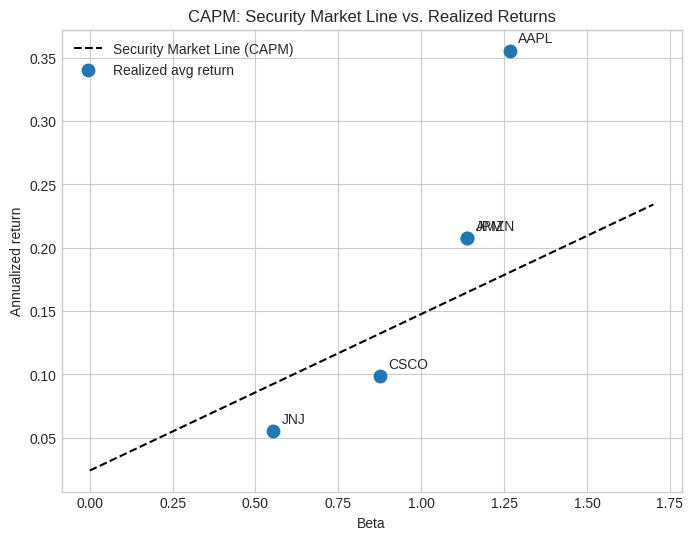

In [10]:
fig, ax = plt.subplots(figsize=(8, 6))

betas = np.linspace(0, max(beta_df["Beta"].max(), 1.5) + 0.2, 100)
sml = betas * mkt_premium_monthly * 12 + (rf_monthly.mean() * 12)
ax.plot(betas, sml, "k--", label="Security Market Line (CAPM)")

realized = [(returns[s] - rf_monthly).mean() * 12 + rf_monthly.mean() * 12 for s in selected]
ax.scatter(beta_df["Beta"], realized, s=80, c="tab:blue", zorder=3, label="Realized avg return")
for s in selected:
    ax.annotate(s, (beta_df.loc[s, "Beta"], realized[selected.index(s)]),
                textcoords="offset points", xytext=(6, 6))

ax.set_xlabel("Beta")
ax.set_ylabel("Annualized return")
ax.set_title("CAPM: Security Market Line vs. Realized Returns")
ax.legend()
plt.show()

In [11]:
ci_rows = []
for stock in selected:
    y = (returns[stock] - rf_monthly).values
    X = np.column_stack([np.ones(len(market_excess)), market_excess.values])
    ci = sm.OLS(y, X).fit().conf_int()
    ci_rows.append({"Ticker": stock, "95% CI low": ci[1, 0], "95% CI high": ci[1, 1]})

sig = beta_df[["Beta", "Beta p-value"]].copy()
sig["Significant at 5%"] = sig["Beta p-value"] < 0.05
sig = sig.join(pd.DataFrame(ci_rows).set_index("Ticker"))
sig[["Beta", "95% CI low", "95% CI high", "Significant at 5%"]].round(3)

,Beta,95% CI low,95% CI high,Significant at 5%
Ticker,,,,
AMZN,1.139,0.805,1.472,True
AAPL,1.267,1.013,1.521,True
JNJ,0.553,0.355,0.750,True
JPM,1.139,0.882,1.396,True
CSCO,0.874,0.597,1.152,True


In [12]:
for s in selected:
    b = beta_df.loc[s, "Beta"]
    if b > 1:
        desc = "more volatile than the market"
    elif b < 1 and b > 0:
        desc = "less volatile than the market"
    else:
        desc = "weakly or negatively correlated with the market"
    print(f"{s}: beta = {b:.2f} → {desc}; R² = {beta_df.loc[s, 'R-squared']:.2f}")

print(f"\nMarket risk premium (annualized): {mkt_premium_monthly * 12:.2%}")

AMZN: beta = 1.14 → more volatile than the market; R² = 0.40
AAPL: beta = 1.27 → more volatile than the market; R² = 0.59
JNJ: beta = 0.55 → less volatile than the market; R² = 0.31
JPM: beta = 1.14 → more volatile than the market; R² = 0.53
CSCO: beta = 0.87 → less volatile than the market; R² = 0.36

Market risk premium (annualized): 12.36%
